In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
data = pd.read_csv("data_banknote_authentication.txt", header=None)

data.columns = ["Variance", "Skewness", "Curtosis", "Entropy", "Class"]

X = data.iloc[:, :4].values
y = data["Class"].values

print("Dataset Shape:", X.shape)
print("Number of Classes:", len(np.unique(y)))
print("Class Names:", np.unique(y))
print(data.head())

Dataset Shape: (1372, 4)
Number of Classes: 2
Class Names: [0 1]
   Variance  Skewness  Curtosis  Entropy  Class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 1097
Testing Samples: 275


In [4]:
k_values = range(1, 21)
cv_scores = []

for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )

    cv_scores.append(scores.mean())
    print(f"K = {k:2d} | Mean CV Accuracy = {scores.mean():.4f}")

K =  1 | Mean CV Accuracy = 0.9982
K =  2 | Mean CV Accuracy = 0.9982
K =  3 | Mean CV Accuracy = 0.9982
K =  4 | Mean CV Accuracy = 0.9982
K =  5 | Mean CV Accuracy = 0.9982
K =  6 | Mean CV Accuracy = 0.9982
K =  7 | Mean CV Accuracy = 0.9982
K =  8 | Mean CV Accuracy = 0.9982
K =  9 | Mean CV Accuracy = 0.9954
K = 10 | Mean CV Accuracy = 0.9973
K = 11 | Mean CV Accuracy = 0.9954
K = 12 | Mean CV Accuracy = 0.9954
K = 13 | Mean CV Accuracy = 0.9927
K = 14 | Mean CV Accuracy = 0.9927
K = 15 | Mean CV Accuracy = 0.9927
K = 16 | Mean CV Accuracy = 0.9927
K = 17 | Mean CV Accuracy = 0.9909
K = 18 | Mean CV Accuracy = 0.9909
K = 19 | Mean CV Accuracy = 0.9900
K = 20 | Mean CV Accuracy = 0.9900


In [5]:
best_k = list(k_values)[np.argmax(cv_scores)]

print("\nOptimal K:", best_k)
print("Best CV Accuracy:", round(max(cv_scores), 4))


Optimal K: 1
Best CV Accuracy: 0.9982


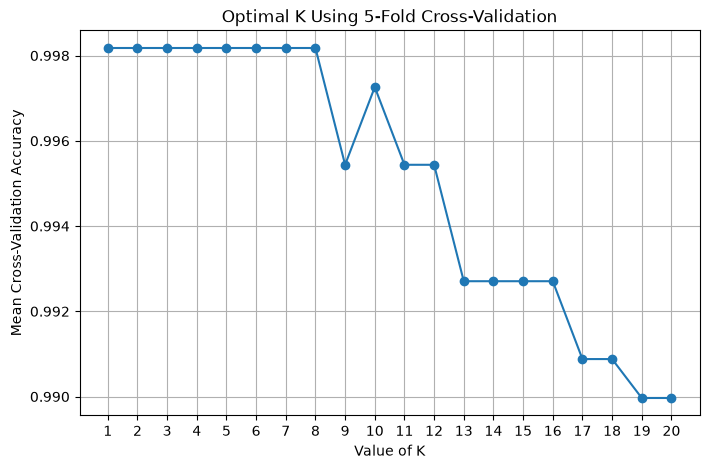

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), cv_scores, marker="o")
plt.xlabel("Value of K")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("Optimal K Using 5-Fold Cross-Validation")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [7]:
final_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=best_k)
)

final_knn.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [8]:
y_pred = final_knn.predict(X_test)

print("Actual Values:", y_test[:20])
print("Predicted Values:", y_pred[:20])

Actual Values: [0 1 0 1 1 1 0 0 0 1 0 1 0 0 0 0 1 1 1 0]
Predicted Values: [0 1 0 1 1 1 0 0 0 1 0 1 0 0 0 0 1 1 1 0]


In [9]:
print("\nTest Set Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Test Set Accuracy: 1.0

Confusion Matrix:
[[153   0]
 [  0 122]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       153
           1       1.00      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275

